# Atelier AI — First LightGBM Ranker

## 1. Experiment contract

Rank 300 historical candidates per customer and return twelve distinct
article_id values.

- Training prediction cutoffs: 2020-08-12, 2020-08-19,
  2020-08-26 and 2020-09-02.
- Each training target covers [cutoff, cutoff + 7 days).
- Candidates and features use information strictly before their cutoff.
- Training uses complete groups containing both binary relevance values.
- Validation target: [2020-09-09, 2020-09-16).
- Issue recommendations for all 20,000 validation customers.
- Compute MAP@12 and macro Recall@12 over customers with observed
  validation purchases, retaining their complete target article sets.
- Buyers with no retrieved positive remain in evaluation and receive
  zero target-based scores.
- Customers without target purchases remain recommendation recipients;
  report their exclusion from target-based metrics.
- Select using full-reference validation MAP@12; retain the simpler
  method on an exact tie.
- Reserve local-test outcomes until model-selection choices are frozen.

The planned model is an LGBMRanker with a LambdaRank objective.
Its scores will not be interpreted as purchase probabilities.

In [1]:
from pathlib import Path
import json

import duckdb
import pandas as pd
import atelier_ai

from atelier_ai.feature_export import file_sha256
from atelier_ai.ranking_data import prepare_ranker_inputs
from atelier_ai.recommendation_features import FEATURE_COLUMNS

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]

VALIDATION_CUTOFF = pd.Timestamp("2020-09-09")
HORIZON_DAYS = 7
TOP_K = 12

RANKER_DATASET = (
    PROJECT_ROOT / "data/processed/ranker_training"
    / "ranker_v1_5e8154a40689"
)
VALIDATION_FEATURE_DATASET = (
    PROJECT_ROOT / "data/processed/features"
    / "validation_2020-09-09_1e4ed94c9d17"
)

ranker_manifest = json.loads(
    (RANKER_DATASET / "manifest.json").read_text()
)
validation_manifest = json.loads(
    (VALIDATION_FEATURE_DATASET / "manifest.json").read_text()
)
training_provenance = ranker_manifest["provenance"]

assert ranker_manifest["status"] == "complete"
assert training_provenance["dataset_split"] == "training"
assert training_provenance["feature_columns"] == FEATURE_COLUMNS
assert pd.Timestamp(
    training_provenance["validation_cutoff"]
) == VALIDATION_CUTOFF

assert validation_manifest["status"] == "complete"
assert validation_manifest["feature_columns"] == FEATURE_COLUMNS
assert pd.Timestamp(validation_manifest["cutoff"]) == VALIDATION_CUTOFF
assert validation_manifest["customers"] == 20_000
assert validation_manifest["candidates_per_customer"] == 300

In [2]:
datasets_to_check = [
    (RANKER_DATASET, ranker_manifest["files"]),
    (
        VALIDATION_FEATURE_DATASET,
        validation_manifest["parts"] + validation_manifest["support_files"],
    ),
]

for directory, records in datasets_to_check:
    for record in records:
        path = directory / record["file"]
        if (
            not path.is_file()
            or path.stat().st_size != record["size_bytes"]
            or file_sha256(path) != record["sha256"]
        ):
            raise ValueError(f"Export file differs from its manifest: {path}")

ranking_source = PROJECT_ROOT / "src/atelier_ai/ranking_data.py"
assert file_sha256(ranking_source) == (
    training_provenance["ranking_data_source_sha256"]
)

print("Training and validation export checksums verified.")

Training and validation export checksums verified.


In [3]:
with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    ranker_training_rows = connection.execute(
        "SELECT * FROM read_parquet(?)",
        [str(RANKER_DATASET / "training_rows.parquet")],
    ).df()

    saved_group_index = connection.execute(
        "SELECT * FROM read_parquet(?) ORDER BY cutoff, customer_id",
        [str(RANKER_DATASET / "groups.parquet")],
    ).df()

ranker_inputs = prepare_ranker_inputs(
    ranker_training_rows,
    validation_cutoff=VALIDATION_CUTOFF,
)

X_train = ranker_inputs["X"]
y_train = ranker_inputs["y"]
train_group_sizes = ranker_inputs["groups"]
training_group_index = ranker_inputs["group_index"]

pd.testing.assert_frame_equal(
    training_group_index,
    saved_group_index,
    check_dtype=False,
)

expected_cutoffs = pd.to_datetime([
    "2020-08-12", "2020-08-19", "2020-08-26", "2020-09-02",
])
assert pd.Index(training_group_index["cutoff"].unique()).equals(
    pd.Index(expected_cutoffs)
)
assert (
    training_group_index["cutoff"] + pd.Timedelta(days=HORIZON_DAYS)
).le(VALIDATION_CUTOFF).all()

assert len(X_train) == training_provenance["training_rows"]
assert len(train_group_sizes) == training_provenance["training_groups"]
assert int(y_train.sum()) == training_provenance["positive_labels"]
assert len(X_train) == len(y_train) == int(train_group_sizes.sum())
assert (train_group_sizes == 300).all()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Training groups:", len(train_group_sizes))
print("Positive labels:", int(y_train.sum()))
print("Zero labels:", int(y_train.eq(0).sum()))

X_train shape: (532500, 17)
y_train shape: (532500,)
Training groups: 1775
Positive labels: 2753
Zero labels: 529747


## 2. Ranking metric contract

Reuse the baseline scoring definition through the project package.

Each score describes one customer–target-week pair. Reference targets
include all distinct purchased articles, including retrieval misses.

AP@k accounts for recommendation order. Recall@k measures the fraction
of target articles retrieved. MAP@12 will average customer AP@12 values
over the full metric-eligible validation population.

The following example is synthetic and is not model performance.

In [4]:
from atelier_ai.ranking_metrics import score_recommendation_list

synthetic_scores = score_recommendation_list(
    relevant_articles={"a", "b", "c"},
    recommended_articles=["a", "x", "b"],
    k=3,
)

assert synthetic_scores["n_target_articles"] == 3
assert synthetic_scores["n_hits"] == 2
assert abs(synthetic_scores["ap_at_k"] - 5 / 9) < 1e-12
assert abs(synthetic_scores["recall_at_k"] - 2 / 3) < 1e-12

pd.Series(synthetic_scores, name="synthetic_example")

n_target_articles    3.000000
n_hits               2.000000
ap_at_k              0.555556
recall_at_k          0.666667
Name: synthetic_example, dtype: float64

## 3. Complete validation reference

Collect cohort transactions in [2020-09-09, 2020-09-16), retaining
source repetitions.

Build two separate tables:
- validation_targets: distinct customer–article target pairs;
- validation_population: all cohort customers and their target-item counts.

Reference targets are constructed independently of candidate retrieval.
All target purchases remain available for evaluation.

In [5]:
from hashlib import sha256

from atelier_ai.data_io import read_source_csv, read_source_chunks
from atelier_ai.temporal import interval_mask

cohort = read_source_csv(
    VALIDATION_FEATURE_DATASET / "cohort.csv",
    columns=["customer_id"],
)
cohort_ids = pd.Index(cohort["customer_id"], name="customer_id")

assert len(cohort_ids) == 20_000
assert cohort_ids.is_unique and not cohort_ids.isna().any()

cohort_sha256 = sha256(
    "\n".join(sorted(cohort_ids)).encode("utf-8")
).hexdigest()
assert cohort_sha256 == validation_manifest["provenance"]["cohort_sha256"]

source_manifest_path = PROJECT_ROOT / "docs/data_manifest.json"
assert file_sha256(source_manifest_path) == (
    validation_manifest["provenance"]["source_manifest_sha256"]
)
source_manifest = json.loads(source_manifest_path.read_text())
for record in source_manifest["files"]:
    assert (PROJECT_ROOT / record["path"]).stat().st_size == record["size_bytes"]

VALIDATION_END = VALIDATION_CUTOFF + pd.Timedelta(days=HORIZON_DAYS)

In [6]:
validation_parts = []

with read_source_chunks(
    PROJECT_ROOT / "data/raw/hm/transactions_train.csv",
    columns=["t_dat", "customer_id", "article_id"],
    chunk_rows=500_000,
) as chunks:
    for chunk_number, chunk in enumerate(chunks, start=1):
        selected = chunk.loc[chunk["customer_id"].isin(cohort_ids)].copy()
        selected["t_dat"] = pd.to_datetime(
            selected["t_dat"], format="%Y-%m-%d", errors="raise"
        )
        selected = selected.loc[
            interval_mask(selected["t_dat"], VALIDATION_CUTOFF, VALIDATION_END)
        ]
        if not selected.empty:
            validation_parts.append(selected)
        if chunk_number % 10 == 0:
            print(f"Reading source chunk {chunk_number}...")

if not validation_parts:
    raise ValueError("No validation transactions found; check source and cohort.")

validation_target_transactions = (
    pd.concat(validation_parts, ignore_index=True)
    .sort_values(["t_dat", "customer_id", "article_id"])
    .reset_index(drop=True)
)
del validation_parts

assert interval_mask(
    validation_target_transactions["t_dat"], VALIDATION_CUTOFF, VALIDATION_END
).all()

print("Validation source rows:", len(validation_target_transactions))

Reading source chunk 10...
Reading source chunk 20...
Reading source chunk 30...
Reading source chunk 40...
Reading source chunk 50...
Reading source chunk 60...
Validation source rows: 3454


In [7]:
validation_targets = (
    validation_target_transactions[["customer_id", "article_id"]]
    .drop_duplicates()
    .sort_values(["customer_id", "article_id"])
    .reset_index(drop=True)
)

assert validation_targets["article_id"].notna().all()
assert validation_targets["article_id"].str.strip().ne("").all()
assert validation_targets["customer_id"].isin(cohort_ids).all()

validation_target_counts = (
    validation_targets.groupby("customer_id")
    .size()
    .rename("n_target_articles")
    .reset_index()
)

validation_population = cohort.merge(
    validation_target_counts,
    on="customer_id",
    how="left",
    validate="one_to_one",
)
validation_population["n_target_articles"] = (
    validation_population["n_target_articles"].fillna(0).astype("int64")
)
validation_population["has_target_purchase"] = (
    validation_population["n_target_articles"].gt(0)
)

validation_relevant_articles = (
    validation_targets.groupby("customer_id")["article_id"].agg(set).to_dict()
)

assert len(validation_population) == len(cohort)
assert validation_population["customer_id"].is_unique
assert int(validation_population["n_target_articles"].sum()) == len(validation_targets)
assert len(validation_relevant_articles) == int(
    validation_population["has_target_purchase"].sum()
)

print("Distinct target pairs:", len(validation_targets))
print("Metric-eligible customers:", len(validation_relevant_articles))

Distinct target pairs: 3073
Metric-eligible customers: 1015


                   status  customers  share_pct
Observed target purchases       1015      5.075
       No target purchase      18985     94.925


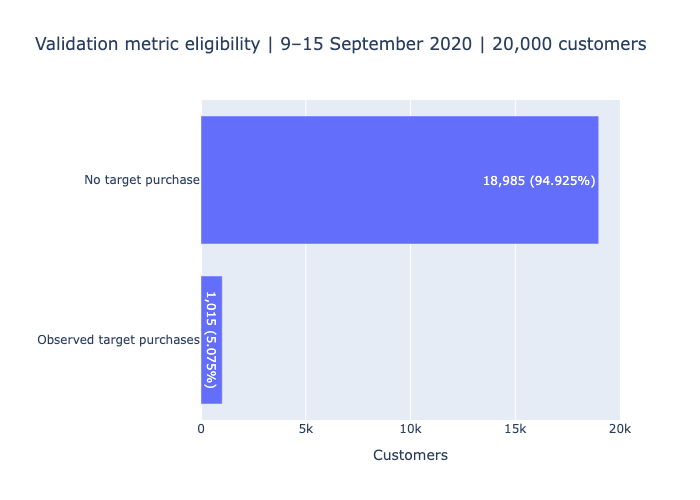

In [8]:
import plotly.express as px

n_with_target = int(validation_population["has_target_purchase"].sum())
n_without_target = len(validation_population) - n_with_target

eligibility_summary = pd.DataFrame({
    "status": ["Observed target purchases", "No target purchase"],
    "customers": [n_with_target, n_without_target],
})
eligibility_summary["share_pct"] = (
    100 * eligibility_summary["customers"] / len(validation_population)
)

# Reconcile with the saved notebook 03 reference.
assert len(validation_target_transactions) == 3_454
assert len(validation_targets) == 3_073
assert n_with_target == 1_015
assert n_without_target == 18_985

print(eligibility_summary.to_string(index=False))

fig = px.bar(
    eligibility_summary,
    x="customers",
    y="status",
    orientation="h",
    text=[
        f"{count:,} ({share:.3f}%)"
        for count, share in zip(
            eligibility_summary["customers"], eligibility_summary["share_pct"]
        )
    ],
    labels={"customers": "Customers", "status": ""},
    title="Validation metric eligibility | 9–15 September 2020 | 20,000 customers",
)
fig.update_layout(
    xaxis_range=[0, len(validation_population)],
    showlegend=False,
)
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

## 4. Cohort-level evaluation contract

Validate recommendation lists for every recipient, then evaluate every
buyer against their complete target set.

MAP and macro Recall assign equal weight to eligible customers.
Micro Recall pools retrieved and reference customer–article pairs.

The following three-customer example is synthetic. It checks evaluation
behavior and does not measure model performance.

customer_id  n_target_articles  n_hits  ap_at_k  recall_at_k
          u                  2       1      0.5          0.5
          v                  1       0      0.0          0.0
recommendation_customers     3.000000
evaluated_customers          2.000000
excluded_customers           1.000000
excluded_share_pct          33.333333
target_pairs                 3.000000
retrieved_target_pairs       1.000000
map_at_k                     0.250000
recall_at_k                  0.250000
micro_recall_at_k            0.333333


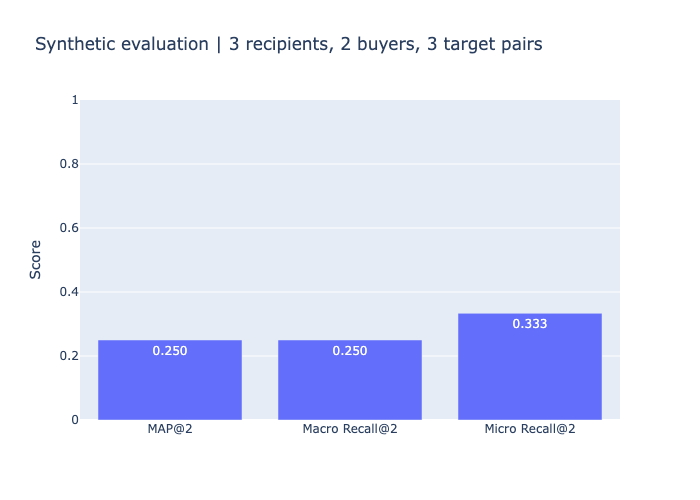

In [9]:
import importlib
import atelier_ai.ranking_metrics as ranking_metrics

importlib.reload(ranking_metrics)

demo_evaluation = ranking_metrics.evaluate_recommendations(
    recommendation_lists={
        "u": ["a", "x"],
        "v": ["q", "r"],
        "w": ["m", "n"],
    },
    relevant_articles={"u": {"a", "b"}, "v": {"missed"}},
    customer_ids=["u", "v", "w"],
    k=2,
)

assert demo_evaluation["summary"]["evaluated_customers"] == 2
assert demo_evaluation["summary"]["target_pairs"] == 3

print(demo_evaluation["customer_scores"].to_string(index=False))
print(pd.Series(demo_evaluation["summary"]).to_string())

demo_metric_summary = pd.DataFrame({
    "metric": ["MAP@2", "Macro Recall@2", "Micro Recall@2"],
    "value": [
        demo_evaluation["summary"][metric]
        for metric in ["map_at_k", "recall_at_k", "micro_recall_at_k"]
    ],
})

fig = px.bar(
    demo_metric_summary,
    x="metric",
    y="value",
    text_auto=".3f",
    title="Synthetic evaluation | 3 recipients, 2 buyers, 3 target pairs",
    labels={"metric": "", "value": "Score"},
)
fig.update_yaxes(range=[0, 1])
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

## 5. Initial LightGBM configuration

Declare a fixed initial LambdaRank configuration before fitting.

Training uses the selected historical groups and their seventeen features.
The first run uses a fixed tree budget without early stopping.

LambdaRank uses an NDCG-related ranking objective. Model selection remains
based on full-reference validation MAP@12.

This configuration is an initial experiment, not an established optimum.
No model is fitted in this section.

In [10]:
import sys
from importlib.metadata import version

import lightgbm as lgb

print("Python executable:", sys.executable)

runtime_versions = {
    package: version(package)
    for package in ["lightgbm", "scikit-learn", "numpy", "pandas"]
}
print(json.dumps(runtime_versions, indent=2))

assert lgb.__version__ == "4.7.0"

RANKER_PARAMS = {
    "objective": "lambdarank",
    "boosting_type": "gbdt",
    "n_estimators": 100,
    "learning_rate": 0.05,
    "num_leaves": 15,
    "max_depth": -1,
    "min_child_samples": 20,
    "label_gain": [0, 1],
    "lambdarank_truncation_level": 15,
    "lambdarank_norm": True,
    "use_missing": True,
    "zero_as_missing": False,
    "random_state": 42,
    "n_jobs": 4,
    "device_type": "cpu",
    "deterministic": True,
    "force_col_wise": True,
}

ranker = lgb.LGBMRanker(**RANKER_PARAMS)

experiment_spec = {
    "experiment_id": "lightgbm_lambdarank_v1_fixed100",
    "training_dataset_fingerprint": ranker_manifest["fingerprint"],
    "validation_dataset_fingerprint": validation_manifest["fingerprint"],
    "selection_metric": "full_reference_validation_map_at_12",
    "early_stopping": False,
    "model_parameters": ranker.get_params(deep=False),
    "runtime_versions": runtime_versions,
}

print(json.dumps(experiment_spec, indent=2))

Python executable: /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/bin/python
{
  "lightgbm": "4.7.0",
  "scikit-learn": "1.9.1",
  "numpy": "2.5.4",
  "pandas": "3.0.6"
}
{
  "experiment_id": "lightgbm_lambdarank_v1_fixed100",
  "training_dataset_fingerprint": "5e8154a40689a6049fd808fa0b02b2a4e61c422391b3ed42f12750cb4d0387e9",
  "validation_dataset_fingerprint": "1e4ed94c9d1716f024c3105f0a095fe93952568a098f51645357d6efcf476d5a",
  "selection_metric": "full_reference_validation_map_at_12",
  "early_stopping": false,
  "model_parameters": {
    "boosting_type": "gbdt",
    "class_weight": null,
    "colsample_bytree": 1.0,
    "importance_type": "split",
    "learning_rate": 0.05,
    "max_depth": -1,
    "min_child_samples": 20,
    "min_child_weight": 0.001,
    "min_split_gain": 0.0,
    "n_estimators": 100,
    "n_jobs": 4,
    "num_leaves": 15,
    "objective": "lambdarank",
    "random_state": 42,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,
    "subsample": 1.0,
    "su

## 6. Fit the first historical ranker

Fit the declared configuration on the selected historical training groups.

Each group contains 300 candidate articles for one customer and cutoff.
All target windows end no later than the validation cutoff.

Use the fixed tree budget without early stopping or additional sample weights.
Validation purchases are reserved for the subsequent evaluation.

Training completion and runtime do not establish recommendation quality.

In [11]:
from time import perf_counter

assert X_train.columns.tolist() == FEATURE_COLUMNS
assert X_train.index.equals(y_train.index)
assert len(X_train) == len(y_train) == int(train_group_sizes.sum())
assert len(train_group_sizes) == len(training_group_index)
assert (train_group_sizes == 300).all()
assert y_train.isin([0, 1]).all()
assert (
    training_group_index["cutoff"] + pd.Timedelta(days=HORIZON_DAYS)
).le(VALIDATION_CUTOFF).all()

# Start from a fresh estimator with the recorded configuration.
ranker = lgb.LGBMRanker(**RANKER_PARAMS)
assert ranker.get_params(deep=False) == experiment_spec["model_parameters"]

fit_start = perf_counter()

ranker.fit(
    X_train,
    y_train,
    group=train_group_sizes,
    feature_name=FEATURE_COLUMNS,
    categorical_feature=[],
)

fit_seconds = perf_counter() - fit_start

assert ranker.n_features_in_ == len(FEATURE_COLUMNS)
assert ranker.feature_name_ == FEATURE_COLUMNS
assert ranker.objective_ == "lambdarank"
assert 0 < ranker.n_estimators_ <= RANKER_PARAMS["n_estimators"]

training_run_summary = {
    "training_rows": len(X_train),
    "training_groups": len(train_group_sizes),
    "model_features": ranker.n_features_in_,
    "positive_labels": int(y_train.sum()),
    "requested_iterations": RANKER_PARAMS["n_estimators"],
    "actual_iterations": int(ranker.n_estimators_),
    "fit_seconds": fit_seconds,
}

print(json.dumps(training_run_summary, indent=2))

[LightGBM] [Info] Total Bins 1649
[LightGBM] [Info] Number of data points in the train set: 532500, number of used features: 17
{
  "training_rows": 532500,
  "training_groups": 1775,
  "model_features": 17,
  "positive_labels": 2753,
  "requested_iterations": 100,
  "actual_iterations": 100,
  "fit_seconds": 1.2246167909906944
}


In [12]:
from hashlib import sha256

experiment_fingerprint = sha256(
    json.dumps(experiment_spec, sort_keys=True).encode("utf-8")
).hexdigest()

MODEL_DIRECTORY = (
    PROJECT_ROOT / "data/processed/models"
    / f"{experiment_spec['experiment_id']}_{experiment_fingerprint[:12]}"
)

model_text = ranker.booster_.model_to_string()
model_metadata = {
    **experiment_spec,
    "feature_columns": FEATURE_COLUMNS,
    "actual_iterations": int(ranker.n_estimators_),
    "model_sha256": sha256(model_text.encode("utf-8")).hexdigest(),
}

payloads = {
    "model.txt": model_text,
    "metadata.json": json.dumps(model_metadata, indent=2) + "\n",
}

MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)

# Reuse identical artifacts; reject conflicting existing contents.
for filename, content in payloads.items():
    path = MODEL_DIRECTORY / filename
    if path.exists() and path.read_text(encoding="utf-8") != content:
        raise FileExistsError(f"Existing model artifact differs: {path}")

for filename, content in payloads.items():
    path = MODEL_DIRECTORY / filename
    if not path.exists():
        path.write_text(content, encoding="utf-8")

assert file_sha256(MODEL_DIRECTORY / "model.txt") == model_metadata["model_sha256"]

reloaded_booster = lgb.Booster(
    model_file=str(MODEL_DIRECTORY / "model.txt")
)
assert reloaded_booster.feature_name() == FEATURE_COLUMNS
assert reloaded_booster.num_trees() == ranker.booster_.num_trees()

print("Verified model directory:", MODEL_DIRECTORY)

Verified model directory: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/models/lightgbm_lambdarank_v1_fixed100_86c845e1cc70


## 7. Validation recommendations and full-reference evaluation

Reload the saved model and score validation candidates in existing
customer-complete partitions.

For every customer, select twelve distinct articles by descending score.
Break exact score ties by ascending article_id.

Issue recommendations for every cohort customer. Evaluate all observed
validation buyers against their complete target sets.

Scores order candidates within a customer; they are not purchase probabilities.

In [13]:
import numpy as np
from time import perf_counter

saved_model_metadata = json.loads(
    (MODEL_DIRECTORY / "metadata.json").read_text()
)
assert file_sha256(MODEL_DIRECTORY / "model.txt") == (
    saved_model_metadata["model_sha256"]
)
assert saved_model_metadata["validation_dataset_fingerprint"] == (
    validation_manifest["fingerprint"]
)
assert saved_model_metadata["feature_columns"] == FEATURE_COLUMNS

validation_booster = lgb.Booster(
    model_file=str(MODEL_DIRECTORY / "model.txt")
)
assert validation_booster.feature_name() == FEATURE_COLUMNS

prediction_batches = []
seen_customers = set()
scored_rows = 0
validation_start = perf_counter()

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    for part_number, part in enumerate(validation_manifest["parts"], start=1):
        path = VALIDATION_FEATURE_DATASET / part["file"]
        assert file_sha256(path) == part["sha256"]

        batch = connection.execute(
            "SELECT * FROM read_parquet(?)",
            [str(path)],
        ).df()

        batch_customers = set(batch["customer_id"])
        assert len(batch) == part["rows"]
        assert batch["cutoff"].eq(VALIDATION_CUTOFF).all()
        assert batch_customers.issubset(set(cohort_ids))
        assert seen_customers.isdisjoint(batch_customers)
        assert not batch.duplicated(["customer_id", "article_id"]).any()
        assert batch.groupby("customer_id").size().eq(300).all()

        scores = validation_booster.predict(
            batch[FEATURE_COLUMNS],
            validate_features=True,
            num_threads=4,
        )
        assert scores.shape == (len(batch),)
        assert np.isfinite(scores).all()

        ranked = (
            batch[["cutoff", "customer_id", "article_id"]]
            .assign(score=scores)
            .sort_values(
                ["customer_id", "score", "article_id"],
                ascending=[True, False, True],
                kind="stable",
            )
            .groupby("customer_id", sort=False)
            .head(TOP_K)
            .copy()
        )
        ranked["rank"] = (
            ranked.groupby("customer_id", sort=False).cumcount() + 1
        )

        prediction_batches.append(ranked)
        seen_customers.update(batch_customers)
        scored_rows += len(batch)

        if part_number % 10 == 0:
            print(f"Scored partitions: {part_number}")

validation_recommendations = (
    pd.concat(prediction_batches, ignore_index=True)
    .sort_values(["customer_id", "rank"])
    .reset_index(drop=True)
)

validation_pipeline_seconds = perf_counter() - validation_start

assert scored_rows == validation_manifest["rows"] == 6_000_000
assert seen_customers == set(cohort_ids)
assert len(validation_recommendations) == len(cohort_ids) * TOP_K
assert validation_recommendations.groupby("customer_id").size().eq(TOP_K).all()
assert not validation_recommendations.duplicated(
    ["customer_id", "article_id"]
).any()

print("Scored candidate rows:", scored_rows)
print("Recommendation recipients:", len(seen_customers))
print("Recommendation rows:", len(validation_recommendations))
print("Read, score and rank seconds:", validation_pipeline_seconds)

Scored partitions: 10
Scored partitions: 20
Scored partitions: 30
Scored partitions: 40
Scored candidate rows: 6000000
Recommendation recipients: 20000
Recommendation rows: 240000
Read, score and rank seconds: 5.873248334013624


{
  "recommendation_customers": 20000,
  "evaluated_customers": 1015,
  "excluded_customers": 18985,
  "excluded_share_pct": 94.925,
  "target_pairs": 3073,
  "retrieved_target_pairs": 90,
  "map_at_k": 0.02049503826509456,
  "recall_at_k": 0.037645798372399356,
  "micro_recall_at_k": 0.0292873413602343
}


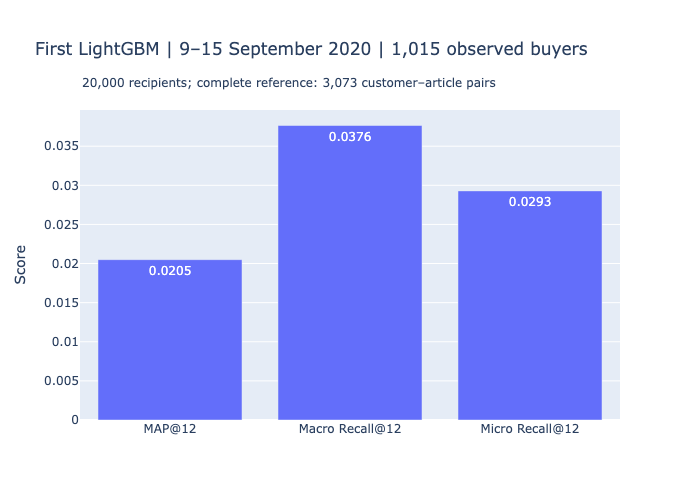

In [14]:
validation_recommendation_lists = (
    validation_recommendations.groupby("customer_id", sort=False)["article_id"]
    .agg(list)
    .to_dict()
)

validation_evaluation = ranking_metrics.evaluate_recommendations(
    recommendation_lists=validation_recommendation_lists,
    relevant_articles=validation_relevant_articles,
    customer_ids=cohort_ids,
    k=TOP_K,
)

validation_model_summary = validation_evaluation["summary"]

assert validation_model_summary["recommendation_customers"] == 20_000
assert validation_model_summary["evaluated_customers"] == 1_015
assert validation_model_summary["excluded_customers"] == 18_985
assert validation_model_summary["target_pairs"] == 3_073

print(json.dumps(validation_model_summary, indent=2))

validation_metric_summary = pd.DataFrame({
    "metric": ["MAP@12", "Macro Recall@12", "Micro Recall@12"],
    "value": [
        validation_model_summary[key]
        for key in ["map_at_k", "recall_at_k", "micro_recall_at_k"]
    ],
})

fig = px.bar(
    validation_metric_summary,
    x="metric",
    y="value",
    text_auto=".4f",
    title="First LightGBM | 9–15 September 2020 | 1,015 observed buyers",
    labels={"metric": "", "value": "Score"},
)
fig.update_yaxes(rangemode="tozero")
fig.add_annotation(
    text="20,000 recipients; complete reference: 3,073 customer–article pairs",
    xref="paper", yref="paper",
    x=0, y=1.12, showarrow=False,
)
fig.update_layout(margin={"t": 110})
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

## 8. Compare the first ranker with the established baselines

Reconstruct the three existing baseline policies from exported historical
source ranks, without using validation purchases.

The current candidate policy preserves all three baseline top-twelve lists.
This property must be rechecked if candidate limits or retrieval policies change.

Evaluate every method with the same recipients, complete reference targets
and metric implementation. Compare unrounded computed values.

In [15]:
from atelier_ai.recommendation_features import combine_candidate_sources

POPULARITY_METHOD = "recent_popularity_7d"
RECENT_METHOD = "recent_purchases_180d_popularity_7d"
CATEGORY_METHOD = "dominant_group_180d_popularity_7d"
MODEL_METHOD = experiment_spec["experiment_id"]

baseline_lists = {
    method: {}
    for method in [POPULARITY_METHOD, RECENT_METHOD, CATEGORY_METHOD]
}


def get_source_orders(frame, rank_column):
    return (
        frame.loc[frame[rank_column].le(TOP_K)]
        .sort_values(["customer_id", rank_column, "article_id"])
        .groupby("customer_id", sort=False)["article_id"]
        .agg(list)
        .to_dict()
    )


baseline_seen_customers = set()
reference_global_top = None

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    for part in validation_manifest["parts"]:
        path = VALIDATION_FEATURE_DATASET / part["file"]
        assert file_sha256(path) == part["sha256"]

        baseline_batch = connection.execute(
            """
            SELECT cutoff, customer_id, article_id, article_recent_rank,
                   history_source_rank, category_source_rank
            FROM read_parquet(?)
            """,
            [str(path)],
        ).df()

        batch_ids = baseline_batch["customer_id"].drop_duplicates().tolist()
        assert baseline_seen_customers.isdisjoint(batch_ids)
        assert baseline_batch["cutoff"].eq(VALIDATION_CUTOFF).all()

        global_top = (
            baseline_batch.loc[
                baseline_batch["article_recent_rank"].le(TOP_K),
                ["article_id", "article_recent_rank"],
            ]
            .drop_duplicates()
            .sort_values("article_recent_rank")["article_id"]
            .tolist()
        )
        assert len(global_top) == len(set(global_top)) == TOP_K

        if reference_global_top is None:
            reference_global_top = global_top
        assert global_top == reference_global_top

        history_orders = get_source_orders(baseline_batch, "history_source_rank")
        category_orders = get_source_orders(baseline_batch, "category_source_rank")

        for customer_id in batch_ids:
            baseline_lists[POPULARITY_METHOD][customer_id] = list(global_top)

            baseline_lists[RECENT_METHOD][customer_id], _ = combine_candidate_sources(
                history_orders.get(customer_id, []), [], global_top,
                budget=TOP_K, history_limit=TOP_K, category_limit=0,
            )

            baseline_lists[CATEGORY_METHOD][customer_id], _ = combine_candidate_sources(
                [], category_orders.get(customer_id, []), global_top,
                budget=TOP_K, history_limit=0, category_limit=TOP_K,
            )

        baseline_seen_customers.update(batch_ids)

assert baseline_seen_customers == set(cohort_ids)
assert all(set(lists) == set(cohort_ids) for lists in baseline_lists.values())

print("Reconstructed baselines:", len(baseline_lists))
print("Recipients per baseline:", len(baseline_seen_customers))

Reconstructed baselines: 3
Recipients per baseline: 20000


In [16]:
method_evaluations = {
    method: ranking_metrics.evaluate_recommendations(
        recommendation_lists=lists,
        relevant_articles=validation_relevant_articles,
        customer_ids=cohort_ids,
        k=TOP_K,
    )
    for method, lists in baseline_lists.items()
}
method_evaluations[MODEL_METHOD] = validation_evaluation

comparison = pd.DataFrame([
    {"method": method, **result["summary"]}
    for method, result in method_evaluations.items()
])

assert comparison["recommendation_customers"].eq(20_000).all()
assert comparison["evaluated_customers"].eq(1_015).all()
assert comparison["target_pairs"].eq(3_073).all()

# Reconcile against notebook 03's displayed MAP and exact hit counts.
saved_baseline_checks = {
    POPULARITY_METHOD: (0.005443, 57),
    RECENT_METHOD: (0.022168, 111),
    CATEGORY_METHOD: (0.004459, 47),
}
for method, (displayed_map, expected_hits) in saved_baseline_checks.items():
    summary = method_evaluations[method]["summary"]
    assert abs(summary["map_at_k"] - displayed_map) <= 0.0000005
    assert summary["retrieved_target_pairs"] == expected_hits

comparison = comparison.sort_values(
    "map_at_k", ascending=False
).reset_index(drop=True)

comparison_columns = [
    "method", "map_at_k", "recall_at_k", "micro_recall_at_k",
    "retrieved_target_pairs", "evaluated_customers", "target_pairs",
]
print(comparison[comparison_columns].to_string(
    index=False, float_format=lambda value: f"{value:.6f}"
))

best_baseline = comparison.loc[
    comparison["method"].isin(baseline_lists)
].iloc[0]

map_gap = (
    validation_model_summary["map_at_k"] - best_baseline["map_at_k"]
)

print("Best baseline:", best_baseline["method"])
print("Model minus best baseline MAP@12:", map_gap)

                             method  map_at_k  recall_at_k  micro_recall_at_k  retrieved_target_pairs  evaluated_customers  target_pairs
recent_purchases_180d_popularity_7d  0.022168     0.044635           0.036121                     111                 1015          3073
    lightgbm_lambdarank_v1_fixed100  0.020495     0.037646           0.029287                      90                 1015          3073
               recent_popularity_7d  0.005443     0.019836           0.018549                      57                 1015          3073
  dominant_group_180d_popularity_7d  0.004459     0.016325           0.015295                      47                 1015          3073
Best baseline: recent_purchases_180d_popularity_7d
Model minus best baseline MAP@12: -0.0016732647833025346


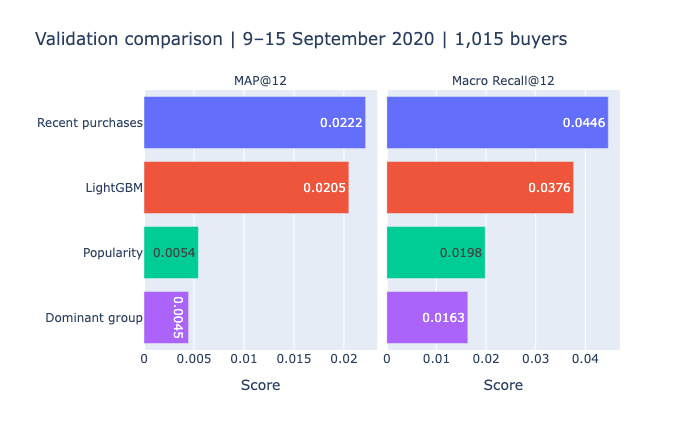

In [17]:
method_labels = {
    POPULARITY_METHOD: "Popularity",
    RECENT_METHOD: "Recent purchases",
    CATEGORY_METHOD: "Dominant group",
    MODEL_METHOD: "LightGBM",
}

comparison_plot = (
    comparison.assign(method_label=comparison["method"].map(method_labels))
    .rename(columns={
        "map_at_k": "MAP@12",
        "recall_at_k": "Macro Recall@12",
    })
    .melt(
        id_vars="method_label",
        value_vars=["MAP@12", "Macro Recall@12"],
        var_name="metric",
        value_name="value",
    )
)

fig = px.bar(
    comparison_plot,
    x="value",
    y="method_label",
    color="method_label",
    facet_col="metric",
    text_auto=".4f",
    category_orders={
        "method_label": comparison["method"].map(method_labels).tolist()
    },
    labels={"value": "Score", "method_label": ""},
    title="Validation comparison | 9–15 September 2020 | 1,015 buyers",
)
fig.update_xaxes(matches=None, rangemode="tozero")
fig.for_each_annotation(lambda annotation: annotation.update(
    text=annotation.text.split("=")[-1]
))
fig.update_layout(showlegend=False, height=430, margin={"t": 90})
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

## 9. Paired error analysis against the recent-purchase baseline

Compare both methods for the same 1,015 validation buyers.

One row represents one customer during [2020-09-09, 2020-09-16).
Keep complete target sets and customers with zero scores.

Define delta AP as model AP minus baseline AP.
Classify customers by positive, negligible or negative delta AP.

This is a descriptive analysis of one validation week.

In [18]:
reference_method = best_baseline["method"]
assert reference_method == RECENT_METHOD

score_columns = [
    "customer_id", "n_target_articles", "n_hits",
    "ap_at_k", "recall_at_k",
]

paired_scores = method_evaluations[MODEL_METHOD]["customer_scores"][
    score_columns
].merge(
    method_evaluations[reference_method]["customer_scores"][score_columns],
    on="customer_id",
    how="outer",
    suffixes=("_model", "_baseline"),
    validate="one_to_one",
    indicator=True,
)

assert paired_scores["_merge"].eq("both").all()
assert len(paired_scores) == 1_015
assert set(paired_scores["customer_id"]) == set(validation_relevant_articles)
assert paired_scores["n_target_articles_model"].eq(
    paired_scores["n_target_articles_baseline"]
).all()

paired_scores["delta_ap"] = (
    paired_scores["ap_at_k_model"] - paired_scores["ap_at_k_baseline"]
)
paired_scores["delta_recall"] = (
    paired_scores["recall_at_k_model"] - paired_scores["recall_at_k_baseline"]
)
paired_scores["delta_hits"] = (
    paired_scores["n_hits_model"] - paired_scores["n_hits_baseline"]
)

EPSILON = 1e-12
outcome_order = ["Improved", "Unchanged", "Worsened"]

paired_scores["ap_outcome"] = "Unchanged"
paired_scores.loc[
    paired_scores["delta_ap"].gt(EPSILON), "ap_outcome"
] = "Improved"
paired_scores.loc[
    paired_scores["delta_ap"].lt(-EPSILON), "ap_outcome"
] = "Worsened"

paired_scores["ap_outcome"] = pd.Categorical(
    paired_scores["ap_outcome"],
    categories=outcome_order,
    ordered=True,
)

assert abs(paired_scores["delta_ap"].mean() - map_gap) < EPSILON
assert int(paired_scores["delta_hits"].sum()) == 90 - 111

In [19]:
outcome_summary = (
    paired_scores.groupby("ap_outcome", observed=False)
    .agg(
        customers=("customer_id", "size"),
        mean_delta_ap=("delta_ap", "mean"),
        sum_delta_ap=("delta_ap", "sum"),
        baseline_hits=("n_hits_baseline", "sum"),
        model_hits=("n_hits_model", "sum"),
    )
    .reset_index()
)

outcome_summary["customer_share_pct"] = (
    100 * outcome_summary["customers"] / len(paired_scores)
)
outcome_summary["map_gap_contribution"] = (
    outcome_summary["sum_delta_ap"] / len(paired_scores)
)

assert int(outcome_summary["customers"].sum()) == len(paired_scores)
assert abs(outcome_summary["customer_share_pct"].sum() - 100) < 1e-10
assert abs(outcome_summary["map_gap_contribution"].sum() - map_gap) < EPSILON

print(outcome_summary.to_string(
    index=False, float_format=lambda value: f"{value:.6f}"
))
print("Reconciled overall MAP gap:", paired_scores["delta_ap"].mean())

ap_outcome  customers  mean_delta_ap  sum_delta_ap  baseline_hits  model_hits  customer_share_pct  map_gap_contribution
  Improved         37       0.108179      4.002634             20          43            3.645320              0.003943
 Unchanged        926       0.000000      0.000000             27          27           91.231527              0.000000
  Worsened         52      -0.109635     -5.700998             64          20            5.123153             -0.005617
Reconciled overall MAP gap: -0.0016732647833025286


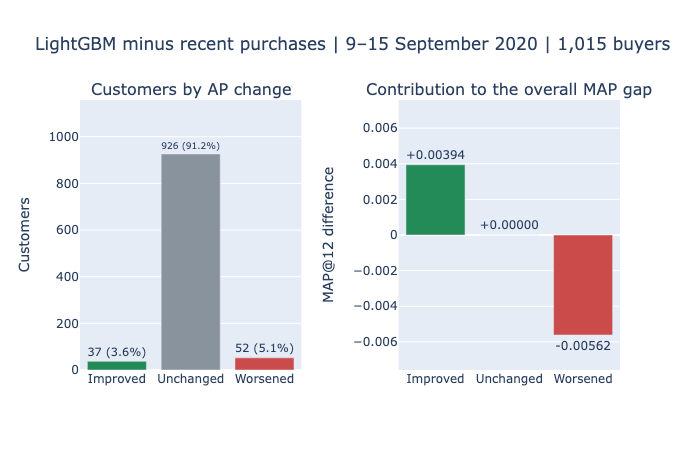

In [20]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

outcome_colors = ["#238B57", "#89939E", "#CB4B4B"]
outcome_labels = outcome_summary["ap_outcome"].astype(str).tolist()

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "Customers by AP change",
        "Contribution to the overall MAP gap",
    ],
    horizontal_spacing=0.18,
)

fig.add_trace(
    go.Bar(
        x=outcome_labels,
        y=outcome_summary["customers"],
        marker_color=outcome_colors,
        text=[
            f"{count:,} ({share:.1f}%)"
            for count, share in zip(
                outcome_summary["customers"],
                outcome_summary["customer_share_pct"],
            )
        ],
        textposition="outside",
        cliponaxis=False,
    ),
    row=1, col=1,
)

fig.add_trace(
    go.Bar(
        x=outcome_labels,
        y=outcome_summary["map_gap_contribution"],
        marker_color=outcome_colors,
        text=[
            f"{value:+.5f}"
            for value in outcome_summary["map_gap_contribution"]
        ],
        textposition="outside",
        cliponaxis=False,
    ),
    row=1, col=2,
)

gap_limit = max(
    float(outcome_summary["map_gap_contribution"].abs().max()) * 1.35,
    1e-6,
)

fig.update_yaxes(
    title_text="Customers",
    range=[0, float(outcome_summary["customers"].max()) * 1.25],
    row=1, col=1,
)
fig.update_yaxes(
    title_text="MAP@12 difference",
    range=[-gap_limit, gap_limit],
    zeroline=True,
    row=1, col=2,
)
fig.update_layout(
    title="LightGBM minus recent purchases | 9–15 September 2020 | 1,015 buyers",
    showlegend=False,
    height=450,
    margin={"t": 100},
)
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

## 10. Validation performance by historical activity

Segment customers using the pre-cutoff customer_has_history feature.

Historical activity covers [2020-03-13, 2020-09-09).
No observed activity in this window does not establish lifetime cold start.

Compare both methods within each segment using complete target sets.
Reconcile segment results with the overall validation metrics.

This remains a descriptive comparison on one validation week.

In [21]:
validation_paths = [
    str(VALIDATION_FEATURE_DATASET / part["file"])
    for part in validation_manifest["parts"]
]

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    customer_history_profile = connection.execute(
        """
        SELECT DISTINCT
            cutoff,
            customer_id,
            customer_has_history AS has_history,
            customer_distinct_articles
        FROM read_parquet(?)
        """,
        [validation_paths],
    ).df()

assert customer_history_profile["cutoff"].eq(VALIDATION_CUTOFF).all()
assert len(customer_history_profile) == len(cohort_ids)
assert customer_history_profile["customer_id"].is_unique
assert set(customer_history_profile["customer_id"]) == set(cohort_ids)
assert customer_history_profile[
    ["has_history", "customer_distinct_articles"]
].notna().all().all()
assert customer_history_profile["has_history"].eq(
    customer_history_profile["customer_distinct_articles"].gt(0)
).all()

paired_history_scores = paired_scores.merge(
    customer_history_profile[
        ["customer_id", "has_history", "customer_distinct_articles"]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one",
)

assert len(paired_history_scores) == len(paired_scores)
assert paired_history_scores["has_history"].notna().all()

history_order = ["No 180-day history", "Has 180-day history"]
paired_history_scores["history_segment"] = pd.Categorical(
    paired_history_scores["has_history"].map({
        False: history_order[0],
        True: history_order[1],
    }),
    categories=history_order,
    ordered=True,
)

In [22]:
history_segment_summary = (
    paired_history_scores.groupby("history_segment", observed=True)
    .agg(
        evaluated_customers=("customer_id", "size"),
        target_pairs=("n_target_articles_model", "sum"),
        baseline_map_at_12=("ap_at_k_baseline", "mean"),
        model_map_at_12=("ap_at_k_model", "mean"),
        baseline_recall_at_12=("recall_at_k_baseline", "mean"),
        model_recall_at_12=("recall_at_k_model", "mean"),
        baseline_hits=("n_hits_baseline", "sum"),
        model_hits=("n_hits_model", "sum"),
        mean_delta_ap=("delta_ap", "mean"),
        sum_delta_ap=("delta_ap", "sum"),
    )
    .reset_index()
)

history_segment_summary["map_gap_contribution"] = (
    history_segment_summary["sum_delta_ap"] / len(paired_history_scores)
)

# Reconcile segment membership with notebook 03.
assert history_segment_summary.set_index("history_segment")[
    "evaluated_customers"
].to_dict() == {
    "No 180-day history": 187,
    "Has 180-day history": 828,
}

assert int(history_segment_summary["target_pairs"].sum()) == 3_073
assert int(history_segment_summary["baseline_hits"].sum()) == 111
assert int(history_segment_summary["model_hits"].sum()) == 90
assert abs(
    history_segment_summary["map_gap_contribution"].sum() - map_gap
) < EPSILON

for segment_metric, overall_metric in [
    ("baseline_map_at_12", best_baseline["map_at_k"]),
    ("model_map_at_12", validation_model_summary["map_at_k"]),
]:
    reconstructed_mean = (
        history_segment_summary[segment_metric]
        * history_segment_summary["evaluated_customers"]
    ).sum() / len(paired_history_scores)
    assert abs(reconstructed_mean - overall_metric) < EPSILON

print(history_segment_summary.to_string(
    index=False, float_format=lambda value: f"{value:.6f}"
))

    history_segment  evaluated_customers  target_pairs  baseline_map_at_12  model_map_at_12  baseline_recall_at_12  model_recall_at_12  baseline_hits  model_hits  mean_delta_ap  sum_delta_ap  map_gap_contribution
 No 180-day history                  187           594            0.002338         0.003681               0.013146            0.016064              7           7       0.001343      0.251135              0.000247
Has 180-day history                  828          2479            0.026647         0.024292               0.051747            0.042520            104          83      -0.002354     -1.949499             -0.001921


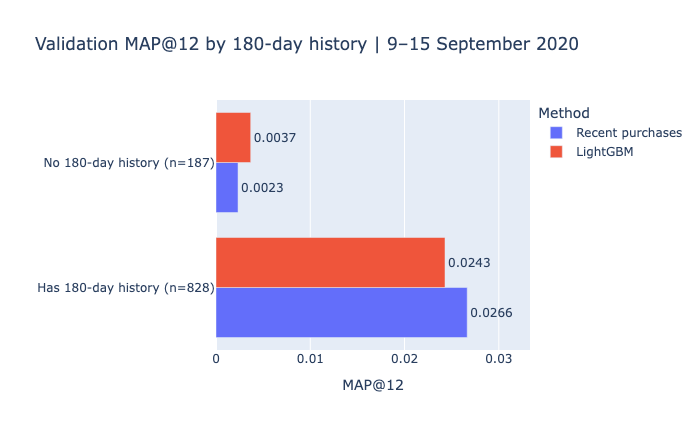

In [23]:
history_segment_summary["segment_label"] = [
    f"{segment} (n={count})"
    for segment, count in zip(
        history_segment_summary["history_segment"],
        history_segment_summary["evaluated_customers"],
    )
]

history_plot = history_segment_summary.melt(
    id_vars=["segment_label", "evaluated_customers", "target_pairs"],
    value_vars=["baseline_map_at_12", "model_map_at_12"],
    var_name="method",
    value_name="map_at_12",
)
history_plot["method"] = history_plot["method"].map({
    "baseline_map_at_12": "Recent purchases",
    "model_map_at_12": "LightGBM",
})

fig = px.bar(
    history_plot,
    x="map_at_12",
    y="segment_label",
    color="method",
    barmode="group",
    orientation="h",
    text_auto=".4f",
    category_orders={
        "segment_label": history_segment_summary["segment_label"].tolist()
    },
    hover_data=["evaluated_customers", "target_pairs"],
    labels={
        "map_at_12": "MAP@12",
        "segment_label": "",
        "method": "Method",
    },
    title="Validation MAP@12 by 180-day history | 9–15 September 2020",
)

fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_xaxes(range=[
    0,
    max(float(history_plot["map_at_12"].max()) * 1.25, 0.001),
])
fig.update_layout(height=430)
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

## 11. First-run findings

The recent-purchase baseline remains the leading method among the four
tested methods on full-reference validation MAP@12:
0.022168 versus 0.020495 for the first LightGBM ranker.

LightGBM improves MAP among the 187 buyers without observed 180-day
history, but underperforms among the 828 buyers with observed history.
The latter segment drives the overall negative MAP difference.

These findings describe one validation week. They do not establish
the causes of the differences or broader temporal robustness.
The local test has not been evaluated.

In [24]:
export_tables = {
    "model_recommendations": validation_recommendations,
    "customer_scores": pd.concat([
        result["customer_scores"].assign(method=method)
        for method, result in method_evaluations.items()
    ], ignore_index=True),
    "method_comparison": comparison,
    "target_transactions": validation_target_transactions,
    "reference_relevance": validation_targets,
    "reference_population": validation_population,
    "paired_history_scores": paired_history_scores.drop(columns="_merge"),
    "paired_outcomes": outcome_summary,
    "history_segments": history_segment_summary.drop(columns="segment_label"),
}

for method, lists in baseline_lists.items():
    export_tables[f"recommendations_{method}"] = pd.DataFrame.from_records(
        (
            (customer_id, article_id, rank)
            for customer_id, articles in lists.items()
            for rank, article_id in enumerate(articles, start=1)
        ),
        columns=["customer_id", "article_id", "rank"],
    )

assert len(export_tables) == 12
assert len(export_tables["customer_scores"]) == 4 * 1_015
assert len(export_tables["reference_relevance"]) == 3_073
assert len(export_tables["reference_population"]) == 20_000
assert len(export_tables["target_transactions"]) == 3_454

for name, frame in export_tables.items():
    if name == "model_recommendations" or name.startswith("recommendations_"):
        assert len(frame) == 240_000

print(pd.DataFrame({
    "table": list(export_tables),
    "rows": [len(frame) for frame in export_tables.values()],
}).to_string(index=False))

                                              table   rows
                              model_recommendations 240000
                                    customer_scores   4060
                                  method_comparison      4
                                target_transactions   3454
                                reference_relevance   3073
                               reference_population  20000
                              paired_history_scores   1015
                                    paired_outcomes      3
                                   history_segments      2
               recommendations_recent_popularity_7d 240000
recommendations_recent_purchases_180d_popularity_7d 240000
  recommendations_dominant_group_180d_popularity_7d 240000


In [25]:
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
from uuid import uuid4
import shutil
import subprocess

exported_at = datetime.now(timezone.utc)
snapshot_id = (
    exported_at.strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
)

EXPERIMENT_OUTPUT_BASE = (
    PROJECT_ROOT / "data/processed/experiments"
    / experiment_spec["experiment_id"]
)
EXPERIMENT_OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
RUN_DIRECTORY = EXPERIMENT_OUTPUT_BASE / snapshot_id

assert not RUN_DIRECTORY.exists()
assert file_sha256(MODEL_DIRECTORY / "model.txt") == (
    saved_model_metadata["model_sha256"]
)

support_files = {
    "model.txt": MODEL_DIRECTORY / "model.txt",
    "model_metadata.json": MODEL_DIRECTORY / "metadata.json",
    "pipeline_notebook.ipynb": (
        PROJECT_ROOT / "notebooks/05_lightgbm_ranker.ipynb"
    ),
    "pyproject.toml": PROJECT_ROOT / "pyproject.toml",
    "uv.lock": PROJECT_ROOT / "uv.lock",
    "training_manifest.json": RANKER_DATASET / "manifest.json",
    "validation_manifest.json": VALIDATION_FEATURE_DATASET / "manifest.json",
    "evaluation.md": PROJECT_ROOT / "docs/evaluation.md",
}

for path in (PROJECT_ROOT / "src/atelier_ai").glob("*.py"):
    support_files[str(path.relative_to(PROJECT_ROOT))] = path

with TemporaryDirectory(
    prefix="staging-", dir=EXPERIMENT_OUTPUT_BASE
) as temporary:
    staging = Path(temporary) / "snapshot"
    staging.mkdir()
    records = []

    with duckdb.connect(
        config={"threads": 2, "memory_limit": "512MB"}
    ) as connection:
        for name, original in export_tables.items():
            frame = original.copy().reset_index(drop=True)
            if "cutoff" not in frame:
                frame.insert(0, "cutoff", VALIDATION_CUTOFF)

            for column in frame.select_dtypes(include="category").columns:
                frame[column] = frame[column].astype("string")

            path = staging / f"{name}.parquet"
            connection.register("_export_frame", frame)
            connection.sql(
                "SELECT * FROM _export_frame"
            ).write_parquet(str(path), compression="zstd")

            differences = connection.execute(
                """
                SELECT count(*) FROM (
                    (SELECT * FROM _export_frame
                     EXCEPT ALL SELECT * FROM read_parquet(?))
                    UNION ALL
                    (SELECT * FROM read_parquet(?)
                     EXCEPT ALL SELECT * FROM _export_frame)
                )
                """,
                [str(path), str(path)],
            ).fetchall()[0][0]

            if differences != 0:
                raise ValueError(f"Parquet round trip differs: {name}")

            connection.unregister("_export_frame")
            records.append({
                "file": path.name,
                "kind": "table",
                "rows": len(frame),
                "size_bytes": path.stat().st_size,
                "sha256": file_sha256(path),
            })

    for name, source in support_files.items():
        destination = staging / name
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(source, destination)
        records.append({
            "file": name,
            "kind": "support",
            "size_bytes": destination.stat().st_size,
            "sha256": file_sha256(destination),
        })

    git_head = subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=PROJECT_ROOT, text=True,
    ).strip()
    git_status = subprocess.check_output(
        ["git", "status", "--porcelain"],
        cwd=PROJECT_ROOT, text=True,
    ).strip()

    run_manifest = {
        "status": "complete",
        "snapshot_id": snapshot_id,
        "exported_at_utc": exported_at.isoformat(),
        "experiment_spec": experiment_spec,
        "model_sha256": saved_model_metadata["model_sha256"],
        "cohort_sha256": cohort_sha256,
        "validation_cutoff": str(VALIDATION_CUTOFF.date()),
        "target_end_exclusive": str(VALIDATION_END.date()),
        "top_k": TOP_K,
        "model_tie_break": "score descending, article_id ascending",
        "metric_summaries": {
            method: result["summary"]
            for method, result in method_evaluations.items()
        },
        "reference_method": reference_method,
        "model_minus_reference_map": float(map_gap),
        "training_run_summary": training_run_summary,
        "validation_pipeline_seconds": validation_pipeline_seconds,
        "local_test_evaluated": False,
        "git": {
            "head": git_head,
            "working_tree_clean": not bool(git_status),
        },
        "files": records,
    }

    (staging / "manifest.json").write_text(
        json.dumps(run_manifest, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )
    staging.rename(RUN_DIRECTORY)

stored_manifest = json.loads((RUN_DIRECTORY / "manifest.json").read_text())
for record in stored_manifest["files"]:
    path = RUN_DIRECTORY / record["file"]
    assert path.stat().st_size == record["size_bytes"]
    assert file_sha256(path) == record["sha256"]

print("Verified experiment snapshot:", RUN_DIRECTORY)
print("Verified Parquet tables:", sum(
    record["kind"] == "table" for record in stored_manifest["files"]
))
print("Working tree clean:", stored_manifest["git"]["working_tree_clean"])

Verified experiment snapshot: /Users/oumar/Developer/portfolio/atelier-ai-project/data/processed/experiments/lightgbm_lambdarank_v1_fixed100/20261024T191410Z_740259cd
Verified Parquet tables: 12
Working tree clean: False
